In [1]:
from teamai.data.loader import load_traces

df = load_traces()

# Identifier chaque séquence d'événements
df["sequence"] = df["events"].map(tuple)

print("Total des blocs :", len(df))
print("Anomalies :", df["label"].sum())
print("Blocs normaux :", (df["label"] == 0).sum())
print("Séquences uniques :", df["sequence"].nunique())

Total des blocs : 575061
Anomalies : 16838
Blocs normaux : 558223
Séquences uniques : 18373


In [2]:
counts = df["sequence"].value_counts()

print("Séquences répétées :", (counts > 1).sum())
print("Blocs appartenant à des séquences répétées :", counts[counts > 1].sum())
print("Occurrences supplémentaires :", len(df) - len(counts))

Séquences répétées : 7409
Blocs appartenant à des séquences répétées : 564097
Occurrences supplémentaires : 556688


In [3]:
labels_per_sequence = df.groupby("sequence")["label"].nunique()

conflicts = labels_per_sequence[labels_per_sequence > 1]

print("Séquences avec labels contradictoires :", len(conflicts))

affected = df[df["sequence"].isin(conflicts.index)]

print("Blocs concernés :", len(affected))
print("Répartition des labels :")
print(affected["label"].value_counts())

Séquences avec labels contradictoires : 10
Blocs concernés : 46
Répartition des labels :
label
1    24
0    22
Name: count, dtype: int64


In [4]:
for label, name in [(0, "Normal"), (1, "Anomalie")]:
    subset = df[df["label"] == label]
    counts_class = subset["sequence"].value_counts()

    print(f"\n--- Classe : {name} ---")
    print("Nombre de blocs :", len(subset))
    print("Séquences uniques :", len(counts_class))
    print("Séquences répétées :", (counts_class > 1).sum())
    print(
        "Blocs appartenant à des séquences répétées :",
        counts_class[counts_class > 1].sum()
    )
    print(
        "Occurrences supplémentaires :",
        len(subset) - len(counts_class)
    )


--- Classe : Normal ---
Nombre de blocs : 558223
Séquences uniques : 14259
Séquences répétées : 6491
Blocs appartenant à des séquences répétées : 550455
Occurrences supplémentaires : 543964

--- Classe : Anomalie ---
Nombre de blocs : 16838
Séquences uniques : 4124
Séquences répétées : 915
Blocs appartenant à des séquences répétées : 13629
Occurrences supplémentaires : 12714


In [5]:
from teamai.paths import PREPROCESSED
import pandas as pd

labels = pd.read_csv(PREPROCESSED / "anomaly_label.csv")

print("Colonnes du fichier :", labels.columns.tolist())
print("Nombre de lignes :", len(labels))
print(labels.head())

Colonnes du fichier : ['BlockId', 'Label']
Nombre de lignes : 575061
                    BlockId    Label
0  blk_-1608999687919862906   Normal
1   blk_7503483334202473044   Normal
2  blk_-3544583377289625738  Anomaly
3  blk_-9073992586687739851   Normal
4   blk_7854771516489510256   Normal


In [6]:
# Vérification de cohérence entre les deux fichiers HDFS

from teamai.paths import PREPROCESSED
import pandas as pd

# Labels de référence
labels_ref = pd.read_csv(
    PREPROCESSED / "anomaly_label.csv"
)

# Séquences et labels déjà chargés via le loader
traces = df[["BlockId", "label"]].copy()

# Conversion des labels de référence
labels_ref["label_ref"] = labels_ref["Label"].map({
    "Normal": 0,
    "Anomaly": 1
})

# Vérifier les identifiants dupliqués
print("BlockId dupliqués dans anomaly_label.csv :",
      labels_ref["BlockId"].duplicated().sum())

print("BlockId dupliqués dans Event_traces.csv :",
      traces["BlockId"].duplicated().sum())

# Vérifier les labels inconnus
print("Labels non reconnus :",
      labels_ref["label_ref"].isna().sum())

# Comparaison par BlockId
comparison = traces.merge(
    labels_ref[["BlockId", "label_ref"]],
    on="BlockId",
    how="outer",
    indicator=True,
    validate="one_to_one"
)

print("\n--- COHÉRENCE DES FICHIERS ---")
print("Blocs présents dans les deux fichiers :",
      (comparison["_merge"] == "both").sum())

print("Blocs absents de anomaly_label.csv :",
      (comparison["_merge"] == "left_only").sum())

print("Blocs absents de Event_traces.csv :",
      (comparison["_merge"] == "right_only").sum())

# Contradictions de labels sur les blocs communs
common = comparison[comparison["_merge"] == "both"]

mismatches = common[
    common["label"] != common["label_ref"]
]

print("Labels contradictoires entre les CSV :",
      len(mismatches))

display(mismatches.head(10))

BlockId dupliqués dans anomaly_label.csv : 0
BlockId dupliqués dans Event_traces.csv : 0
Labels non reconnus : 0

--- COHÉRENCE DES FICHIERS ---
Blocs présents dans les deux fichiers : 575061
Blocs absents de anomaly_label.csv : 0
Blocs absents de Event_traces.csv : 0
Labels contradictoires entre les CSV : 0


,BlockId,label,label_ref,_merge


In [7]:
# SCRUM-18 — Distribution des types d'anomalies

anomalies = df[df["label"] == 1].copy()

distribution = (
    anomalies["anomaly_type"]
    .value_counts(dropna=False)
    .rename_axis("Type")
    .reset_index(name="Nombre")
)

distribution["Pourcentage"] = (
    distribution["Nombre"] / len(anomalies) * 100
).round(2)

print("Nombre total d'anomalies :", len(anomalies))
print("Nombre de types distincts :", anomalies["anomaly_type"].nunique())
print("\nDistribution par type :")

display(distribution)

Nombre total d'anomalies : 16838
Nombre de types distincts : 26

Distribution par type :


,Type,Nombre,Pourcentage
0,5.0,4167,24.75
1,31.0,3225,19.15
2,3.0,2950,17.52
3,0.0,2809,16.68
4,4.0,1240,7.36
5,1.0,953,5.66
6,21.0,724,4.30
7,7.0,476,2.83
8,12.0,130,0.77
9,8.0,45,0.27


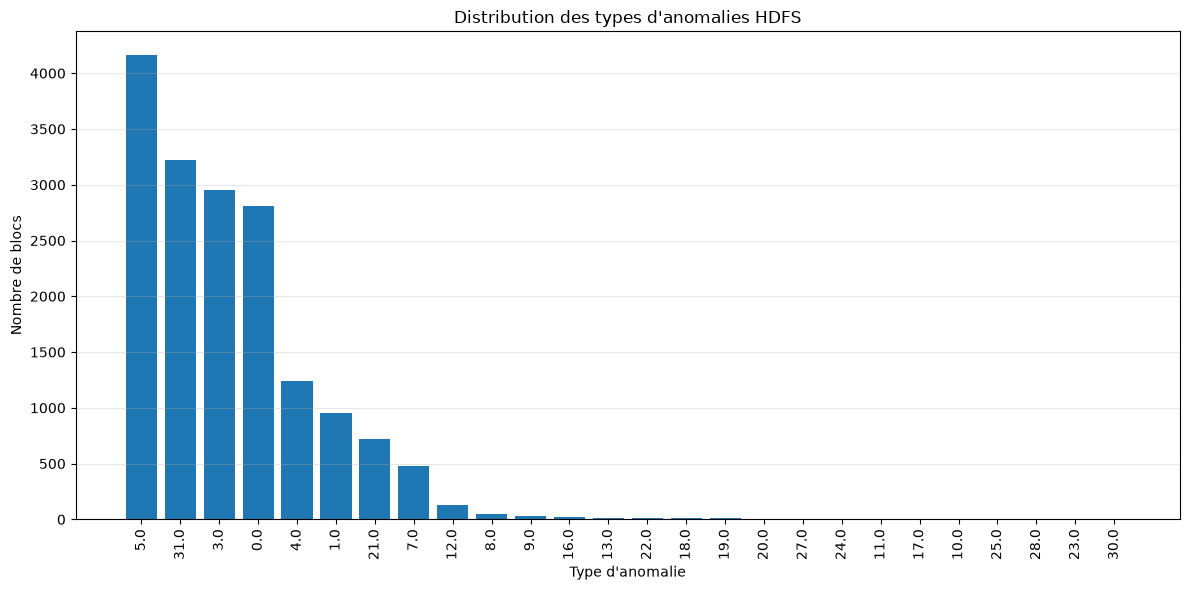

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.bar(
    distribution["Type"].astype(str),
    distribution["Nombre"]
)

plt.title("Distribution des types d'anomalies HDFS")
plt.xlabel("Type d'anomalie")
plt.ylabel("Nombre de blocs")
plt.xticks(rotation=90)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [9]:
print("Types manquants chez les anomalies :",
      anomalies["anomaly_type"].isna().sum())

print("Types présents chez les blocs normaux :")
print(df[df["label"] == 0]["anomaly_type"].value_counts(dropna=False).head())

print("Somme des effectifs par type :", distribution["Nombre"].sum())

print("Types avec moins de 10 blocs :",
      (distribution["Nombre"] < 10).sum())

Types manquants chez les anomalies : 0
Types présents chez les blocs normaux :
anomaly_type
NaN    558223
Name: count, dtype: int64
Somme des effectifs par type : 16838
Types avec moins de 10 blocs : 13
